In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
demand = [

    120,128,135,132,145,153,160,158,170,178,185,195,
    190,202,210,207,220,230,238,235,250,260,268,280,
    275,288,298,295,310,322,330,328,342,355,365,378
]

df = pd.DataFrame({"demand": demand})

df["time"] = np.arange(1, len(df) + 1)

print(df)

    demand  time
0      120     1
1      128     2
2      135     3
3      132     4
4      145     5
5      153     6
6      160     7
7      158     8
8      170     9
9      178    10
10     185    11
11     195    12
12     190    13
13     202    14
14     210    15
15     207    16
16     220    17
17     230    18
18     238    19
19     235    20
20     250    21
21     260    22
22     268    23
23     280    24
24     275    25
25     288    26
26     298    27
27     295    28
28     310    29
29     322    30
30     330    31
31     328    32
32     342    33
33     355    34
34     365    35
35     378    36


In [ ]:
for lag in [1, 2, 3]:
    df[f"lag_{lag}"] = df["demand"].shift(lag)

df["rolling_mean_3"] = df["demand"].shift(1).rolling(window=3).mean()

print(df.head(10))

   demand  time  lag_1  lag_2  lag_3  rolling_mean_3
0     120     1    NaN    NaN    NaN             NaN
1     128     2  120.0    NaN    NaN             NaN
2     135     3  128.0  120.0    NaN             NaN
3     132     4  135.0  128.0  120.0      127.666667
4     145     5  132.0  135.0  128.0      131.666667
5     153     6  145.0  132.0  135.0      137.333333
6     160     7  153.0  145.0  132.0      143.333333
7     158     8  160.0  153.0  145.0      152.666667
8     170     9  158.0  160.0  153.0      157.000000
9     178    10  170.0  158.0  160.0      162.666667


In [ ]:
features = [
    "time",
    "lag_1",
    "lag_2",
    "lag_3",
    "rolling_mean_3"
]

X = df[features]
y = df["demand"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   time  lag_1  lag_2  lag_3  rolling_mean_3
0     1    NaN    NaN    NaN             NaN
1     2  120.0    NaN    NaN             NaN
2     3  128.0  120.0    NaN             NaN
3     4  135.0  128.0  120.0      127.666667
4     5  132.0  135.0  128.0      131.666667

Target Variable:
0    120
1    128
2    135
3    132
4    145
Name: demand, dtype: int64


In [ ]:
split = int(len(df) * 0.80)

X_train, X_test = X.iloc[:split], X.iloc[split:]

y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 28
Testing observations: 8


In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=4,
        random_state=42
    )
}

print("Models defined successfully.")

Models defined successfully.


In [ ]:
results = {}
predictions = {}

# Drop NaN rows from training set caused by lags and rolling window features
clean_idx = X_train.dropna().index
X_train_clean = X_train.loc[clean_idx]
y_train_clean = y_train.loc[clean_idx]

for name, model in models.items():

    # Train the model using the cleaned training data
    model.fit(X_train_clean, y_train_clean)

    # Predict demand for the test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    mape = np.mean(
        np.abs((y_test - y_pred) / y_test)
    ) * 100

    results[name] = [mae, rmse, mape]

    predictions[name] = y_pred

# Create a model comparison table
results_df = pd.DataFrame(
    results,
    index=["MAE", "RMSE", "MAPE (%)"]
).T

print("Model Comparison:")
print(results_df.round(2))

Model Comparison:
                     MAE   RMSE  MAPE (%)
Linear Regression  10.31  12.31      2.93
Decision Tree      47.58  52.28     13.60
Random Forest      46.41  51.22     13.26


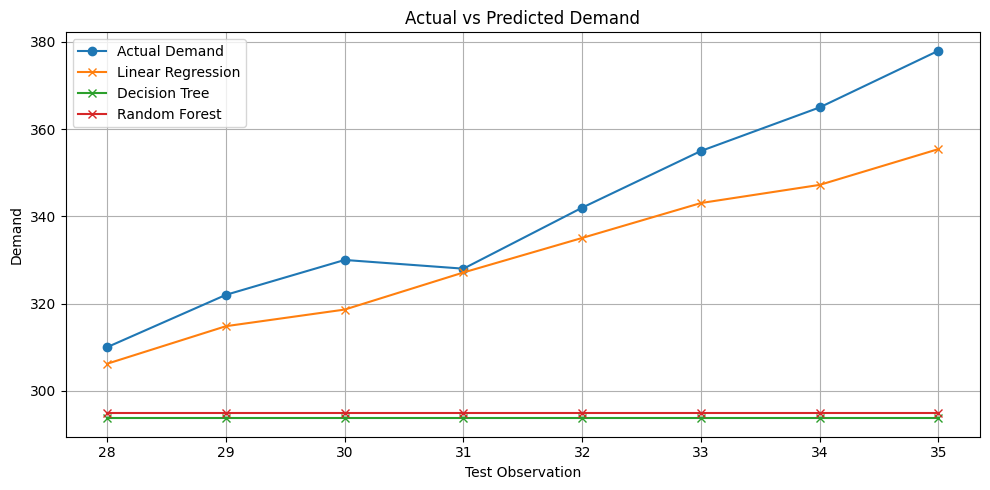

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    y_test.index,
    y_test.values,
    marker="o",
    label="Actual Demand"
)

for name, y_pred in predictions.items():

    plt.plot(
        y_test.index,
        y_pred,
        marker="x",
        label=name
    )

plt.xlabel("Test Observation")
plt.ylabel("Demand")

plt.title("Actual vs Predicted Demand")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

# Train the XGBoost model
xgb_model.fit(X_train, y_train)

# Generate predictions
xgb_pred = xgb_model.predict(X_test)

# Calculate metrics
print("\nXGBoost Metrics:")

print(
    "MAE:",
    round(mean_absolute_error(y_test, xgb_pred), 2)
)

print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_test, xgb_pred)), 2)
)

print(
    "MAPE (%):",
    round(
        np.mean(np.abs((y_test - xgb_pred) / y_test)) * 100,
        2
    )
)


XGBoost Metrics:
MAE: 47.92
RMSE: 52.59
MAPE (%): 13.7
